# Working with the VLM Run Gateway in Pixeltable

The [VLM Run Gateway](https://docs.vlm.run/gateway/introduction) is an OpenAI-compatible API in front of vision and speech models: OCR and document parsing, visual question answering, segmentation, pose estimation, multimodal embeddings and speech-to-text. Pixeltable's `vlmrun_gateway` module turns each of these into a computed column, so images, PDFs and audio in your tables are processed as rows are inserted.

### Prerequisites

- A VLM Run account with an API key ([app.vlm.run](https://app.vlm.run/dashboard/settings/api-keys))

### Important notes

- Gateway usage is billed per token, image, video or audio second, with a minimum of $0.001 per call on most models (not embeddings or the partner Gemini, Kimi, MiniMax and Muse models) ([pricing](https://docs.vlm.run/gateway/pricing)). `chat_completions()` reports each call's cost in `usage.cost`, as does `transcriptions()` in its JSON formats.
- Be mindful of sensitive data and consider security measures when integrating with external services.

First you'll need to install the required libraries and enter your VLM Run API key.

In [1]:
%pip install -qU pixeltable openai

In [2]:
import getpass
import os

if 'VLMRUN_API_KEY' not in os.environ:
    os.environ['VLMRUN_API_KEY'] = getpass.getpass(
        'Enter your VLM Run API key:'
    )

Now let's create a Pixeltable directory to hold the tables for our demo.

In [3]:
import json
import pixeltable as pxt
from pixeltable.functions import vlmrun_gateway

# Remove the 'vlmrun_gateway_demo' directory and its contents, if it exists
pxt.drop_dir('vlmrun_gateway_demo', force=True)
pxt.create_dir('vlmrun_gateway_demo')

SAMPLES = (
    'https://storage.googleapis.com/vlm-data-public-prod/hub/examples'
)

Created directory 'vlmrun_gateway_demo'.


## Read PDFs with OCR

`ocr()` sends a document to an OCR model and returns the Gateway's JSON, whose `pages` list has one record per page. The default model, `paddlepaddle/paddleocr-vl-1.6`, reads each page as Markdown. Use `pages` to read part of a long document. Pages are rasterized at 96 DPI by default; dense tables, like the line items on this invoice, can come back garbled at that resolution, so this example raises `dpi` to 150.

In [4]:
docs = pxt.create_table('vlmrun_gateway_demo/docs', {'doc': pxt.Document})
docs.add_computed_column(pages=vlmrun_gateway.ocr(docs.doc, dpi=150))

# The first page's text, as Markdown
docs.add_computed_column(
    first_page=docs.pages.pages[0].content['items'][0].text
)

Created table 'docs'.
Added 0 column values with 0 errors in 0.01 s
Added 0 column values with 0 errors in 0.01 s


No rows affected.

In [5]:
docs.insert([{'doc': f'{SAMPLES}/document.invoice/sample-invoice.pdf'}])
docs.select(
    npages=docs.pages.document_npages, first_page=docs.first_page
).collect()

Inserted 1 row with 0 errors in 2.68 s (0.37 rows/s)


npages,first_page
3,"cpb CPB SOFTWARE (GERMANY) GMBH Im Bruch 3, 63897 Miltenberg Telefon: +49 9371 9786 0 germany@cpb-software.com www.cpb-software.com CPB Software (Germany) GmbH - Im Bruch 3 - 63897 Miltenberg/Main Musterkunde AG Mr. John Doe Musterstr. 23 12345 Musterstadt Name: Stefanie Müller Phone: +49 9371 9786-0 Invoice WMACESS Internet VAT No. DE199378386 Invoice No Customer No Invoice Period Date 123100401 12345 01 ...... 72,41 € Gross Amount incl. VAT 453,53 € Terms of Payment: Immediate payment without discount. Any bank charges must be paid by the invoice recipient. Bank fees at our expense will be charged to the invoice recipient! Please credit the amount invoiced to IBAN DE29 1234 5678 9012 3456 78 | BIC GENODE51MIC (SEPA Credit Transfer) This invoice is generated automatically and will not be signed"


To get text lines with bounding boxes instead, pick a model and method that return regions, such as `model='paddleocr/pp-ocrv6', method='ocr'`. Each model's methods are listed in the [Gateway docs](https://docs.vlm.run/gateway/methods).

## Extract structured data from images

`chat_completions()` works like the OpenAI endpoint of the same name. Image columns can be referenced directly in messages. With `response_format` set to a JSON schema, the model's reply matches your schema.

In [6]:
receipts = pxt.create_table(
    'vlmrun_gateway_demo/receipts', {'image': pxt.Image}
)
messages = [
    {
        'role': 'user',
        'content': [
            {
                'type': 'text',
                'text': 'Extract the merchant and the total.',
            },
            {'type': 'image_url', 'image_url': receipts.image},
        ],
    }
]
receipt_schema = {
    'type': 'object',
    'properties': {
        'merchant': {'type': 'string'},
        'total': {'type': 'number'},
    },
    'required': ['merchant', 'total'],
}
receipts.add_computed_column(
    response=vlmrun_gateway.chat_completions(
        messages,
        model='qwen/qwen3.8-27b',
        model_kwargs={
            'response_format': {
                'type': 'json_schema',
                'json_schema': {
                    'name': 'receipt',
                    'schema': receipt_schema,
                },
            }
        },
    )
)


# The reply is a JSON string; parse it into a JSON column
@pxt.udf
def parse_json(s: str) -> pxt.Json:
    return json.loads(s)


receipts.add_computed_column(
    receipt=parse_json(receipts.response.choices[0].message.content)
)

Created table 'receipts'.
Added 0 column values with 0 errors in 0.01 s
Added 0 column values with 0 errors in 0.01 s


No rows affected.

In [7]:
receipts.insert(
    [{'image': f'{SAMPLES}/document.receipt/playground/2.jpg'}]
)
receipts.select(
    receipts.receipt, cost=receipts.response.usage.cost
).collect()

Inserted 1 row with 0 errors in 2.62 s (0.38 rows/s)


receipt,cost
"{""total"": 29.73, ""merchant"": ""Walmart""}",0.001


## Segment objects

`analyze()` runs detection, segmentation and pose models. Here `facebook/sam3.1` finds every object that matches a text prompt. Boxes are normalized to the range 0 to 1, and `'mask_format': 'none'` in `method_params` skips the masks. The bridge photo has no cars, so its list is empty.

Created table 'photos'.
Added 0 column values with 0 errors in 0.01 s


Inserted 2 rows with 0 errors in 0.80 s (2.51 rows/s)


image,cars_content_items
,"[{""area"": 0.237, ""label"": ""car"", ""score"": 0.977, ""bbox_xywh"": [0.056, 0.335, 0.875, 0.435], ""instance_id"": 1}]"
,[]

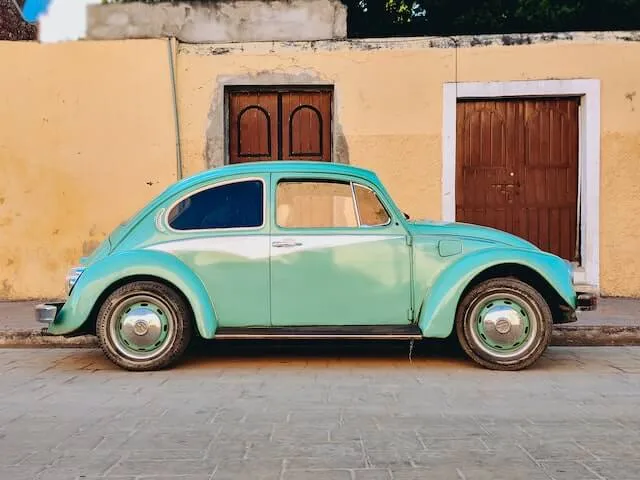
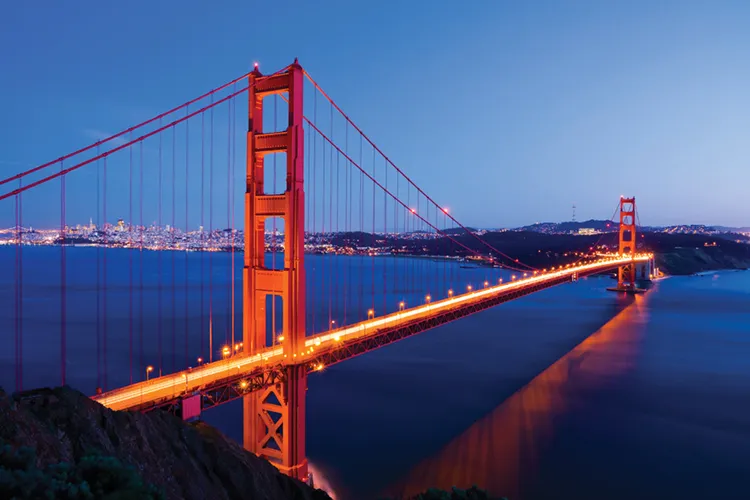

In [8]:
photos = pxt.create_table(
    'vlmrun_gateway_demo/photos', {'image': pxt.Image}
)
photos.add_computed_column(
    cars=vlmrun_gateway.analyze(
        photos.image,
        model='facebook/sam3.1',
        method='segment',
        method_params={'prompt': 'car', 'mask_format': 'none'},
    )
)
photos.insert(
    [
        {'image': f'{SAMPLES}/image.caption/car.jpg'},
        {'image': f'{SAMPLES}/image.generation/sf-golden-gate.jpg'},
    ]
)
photos.select(photos.image, photos.cars.content['items']).collect()

## Search images with text

`embeddings()` puts text and images in one vector space, so an embedding index on an image column can be searched with a text query.

image,similarity
,0.473
,0.208

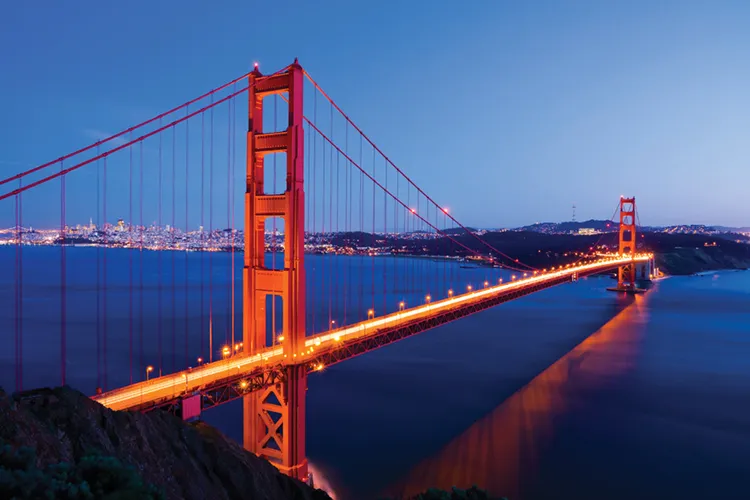
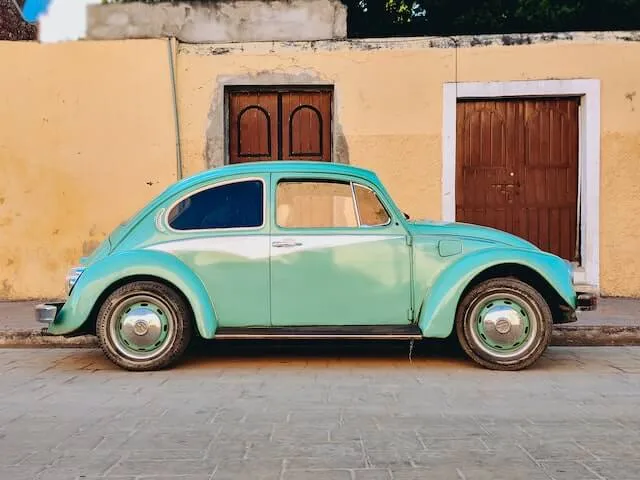

In [9]:
photos.add_embedding_index(
    photos.image,
    embedding=vlmrun_gateway.embeddings.using(
        model='qwen/qwen3-vl-embedding-2b'
    ),
)
sim = photos.image.similarity(string='a bridge over the water')
photos.order_by(sim, asc=False).limit(2).select(
    photos.image, sim
).collect()

## Transcribe audio

`transcriptions()` turns speech in an audio column into text, with `nvidia/parakeet-tdt-0.6b-v3` by default. The sample here is a 10-second clip, so the transcript ends mid-sentence. For timestamps, pass `model_kwargs={'response_format': 'verbose_json', 'timestamp_granularities': ['segment', 'word']}`.

In [10]:
audio = pxt.create_table(
    'vlmrun_gateway_demo/audio', {'audio': pxt.Audio}
)
audio.add_computed_column(
    transcript=vlmrun_gateway.transcriptions(audio.audio)
)
speech = f'{SAMPLES}/audio.transcription-summary/two_minute_rules.mp3'
audio.insert([{'audio': speech}])
audio.select(audio.transcript.text).collect()

Created table 'audio'.
Added 0 column values with 0 errors in 0.01 s


Inserted 1 row with 0 errors in 0.73 s (1.38 rows/s)


transcript_text
"After reading tons of productivity books, I came across so many rules. Like the two-year rule, the five-minute rule, the five-second rule. No, not that five-second rule. The problem is"


## Rate limits

The Gateway allows 240 requests per minute and 10,000 per hour per account, below Pixeltable's default of 600 RPM. To stay under both, set `rate_limit = 160` in the `vlmrun_gateway` section of your Pixeltable config, or set the `VLMRUN_GATEWAY_RATE_LIMIT` environment variable.

### Learn more

- [VLM Run Gateway documentation](https://docs.vlm.run/gateway/introduction)
- [Available models](https://vlm.run/gateway/models)
- [Embedding indexes in Pixeltable](https://docs.pixeltable.com/platform/embedding-indexes)